# Sign Language Recognition Project (SignVision)
Github repository: https://github.com/Nurikoks/SignLanguageRecognition.git 
## Authors
- Nurassyl Kaziyev
- Alua Muratova

## Project Description
This project recognizes American Sign Language (ASL) from a camera. It has two tasks:
24 static letters (A to Y without J and Z) from images, and 25 words with movement (hello,
thank you, water, ...) from video. We compare classical machine learning on hand landmarks
with neural networks and a ready transformer model, also providing a webcam application that shows the models working live.

## Technologies Used
- Python
- MediaPipe (hand and pose landmarks)
- Scikit-learn (SVM, Random Forest)
- PyTorch and torchvision (MobileNetV2, 1D-CNN, GRU)
- Hugging Face Transformers (ViT)
- OpenCV (webcam application)

## Datasets
- ASL Alphabet (training of letters): https://www.kaggle.com/datasets/grassknoted/asl-alphabet
- ASL Alphabet Test (test of letters): https://www.kaggle.com/datasets/danrasband/asl-alphabet-test
- Google Isolated Sign Language Recognition (words): https://www.kaggle.com/competitions/asl-signs

## How to Run
1. Install the libraries: `pip install -r requirements.txt` (and PyTorch with CUDA for the networks).
2. Download the datasets into `data/` and the MediaPipe models (see `README.md` in the repository).
3. Extract the hand landmarks: `extract_features.py`.
4. Train the letter models: `train.py`, `train_mobilenet.py`, test the ready model: `evaluate_vit.py`.
5. Prepare and train the word models: `islr_prepare.py`, `train_islr.py`.
6. Compute all metrics and figures: `evaluate_all.py`.
7. (Optional) Run the webcam application: `webcam_demo.py`.

## Models Used
- Support Vector Machine (letters and words)
- Random Forest (letters and words)
- MobileNetV2, fine-tuned from ImageNet (letters)
- Vision Transformer (ViT), ready model from Hugging Face (letters)
- 1D Convolutional Neural Network (words)
- GRU recurrent neural network (words)

## Notes on this notebook
The notebook runs the project scripts and shows their real output. MobileNetV2 is not trained
again here, because one model takes about 45 minutes on a GPU. We test its saved weights and
show the loss and accuracy that were saved during its training.
The C++ log lines of MediaPipe (for example "Feedback manager requires a model with a single
signature") are removed from the printed output, everything else is shown as it was printed.

### Importing Libraries
The main libraries for data, plots and models are imported.

In [1]:
import platform
from pathlib import Path

import cv2
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, Markdown, display


def show(path, width=900):
    display(Image(filename=str(path), width=width))


def section(md_file, title):
    text = Path(md_file).read_text(encoding="utf-8")
    display(Markdown(text.split("## " + title, 1)[1].split("\n## ", 1)[0]))

### Checking GPU Availability
The neural networks are trained on a GPU with CUDA.

In [2]:
print("Python", platform.python_version(), "| PyTorch", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python 3.13.5 | PyTorch 2.15.0+cu132
,CUDA available: True
,GPU: NVIDIA GeForce RTX 4060 Laptop GPU


# Part 1. Static Letters

### Loading the Letter Dataset
The training set has 3,000 images for each letter. The images are frames of videos with the
same background. The external test set has 30 images for each letter with other people and
backgrounds. We use the 24 static letters, because J and Z need movement.

In [3]:
from extract_features import find_class_folders
from features import LETTERS
from results import is_val, list_images, test_images

train_folders = find_class_folders("data/asl_alphabet_train")
n_train = {l: len(list_images(train_folders[l])) for l in LETTERS}
test = test_images()
print("Letters:", " ".join(LETTERS))
print("Training images:", sum(n_train.values()), "| per letter:", set(n_train.values()))
print("External test images:", len(test), "| per letter:", set(pd.Series([l for _, l in test]).value_counts()))

Letters: A B C D E F G H I K L M N O P Q R S T U V W X Y
,Training images: 72000 | per letter: {3000}
,External test images: 720 | per letter: {30}


### Showing Example Images
The top row shows training images, the bottom row shows test images of the same letters.

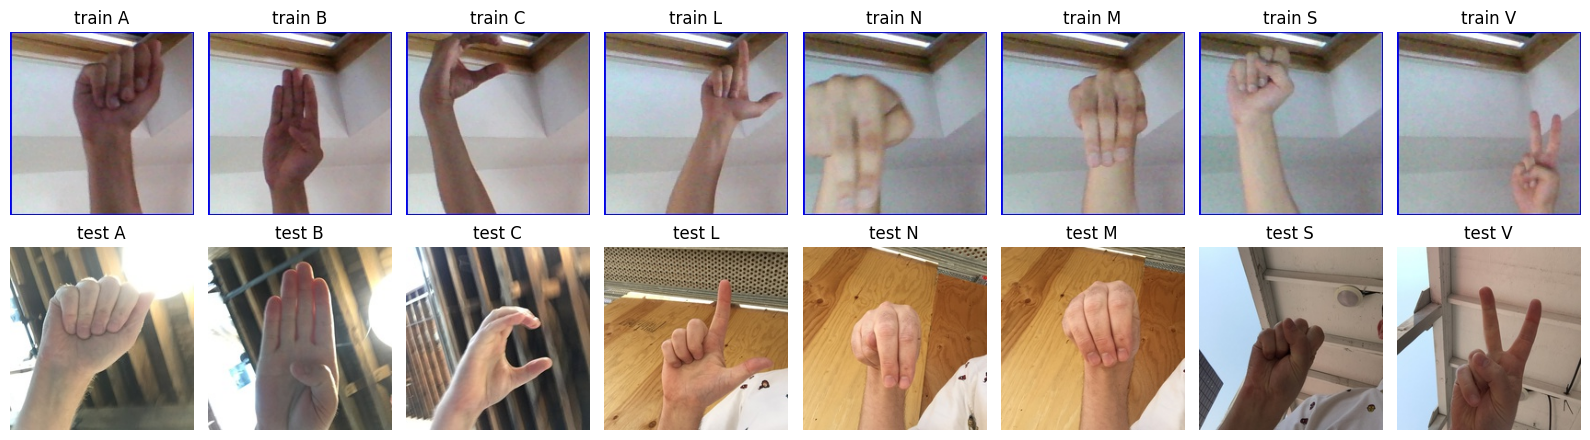

In [4]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for ax, letter in zip(axes[0], "ABCLNMSV"):
    ax.imshow(plt.imread(list_images(train_folders[letter])[100])); ax.set_title("train " + letter); ax.axis("off")
for ax, letter in zip(axes[1], "ABCLNMSV"):
    path = next(p for p, l in test if l == letter)
    ax.imshow(plt.imread(path)); ax.set_title("test " + letter); ax.axis("off")
plt.tight_layout(); plt.show()

### Splitting Training and Validation Data
Neighbouring video frames look almost the same. If we split them at random, the same picture
would be in training and validation. So we split them in blocks of 50 frames in a row, and
every fifth block is used for validation (`results.py`).

In [5]:
files = list_images(train_folders["A"])
val = [is_val(f) for f in files]
print("Letter A, frames 0-299 (V = validation, . = training):")
print("".join("V" if v else "." for v in val[:300]))
print("Validation share:", round(np.mean(val), 3))

Letter A, frames 0-299 (V = validation, . = training):
,VV.VVVVVVVVVV.VVVVVVVVVV.VVVVVVVVVV.VVVVVVVVVV.VVVVVVVVVV.......................................................V..............................................................................................................V........................................................VVVVVVVVVV.VVVVVVVVV
,Validation share: 0.2


### Extracting Hand Landmarks with MediaPipe
MediaPipe finds 21 points of the hand. We move the wrist to (0, 0), divide by the hand size and
mirror the left hand. This gives 63 numbers per image that do not depend on the position and
size of the hand or on which hand is used (`features.py`).

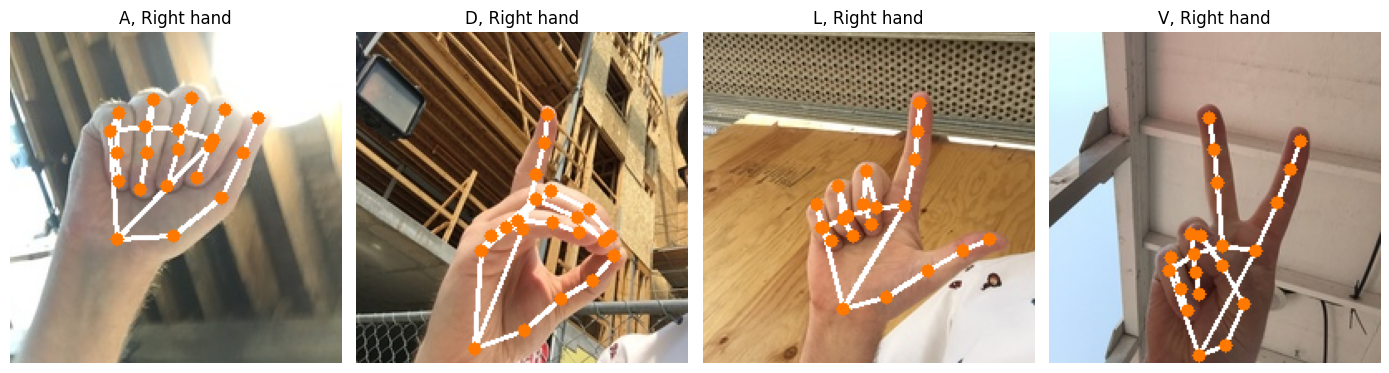

First 9 of the 63 features of the last image: [ 0.     0.     0.     0.115 -0.047 -0.084  0.188 -0.217 -0.12 ]


In [6]:
from features import create_detector, detect, draw_hand, normalize

detector = create_detector()
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, (path, letter) in zip(axes, [test[0], test[90], test[300], test[600]]):
    rgb = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
    points, side = detect(detector, rgb)
    draw_hand(rgb, points, (255, 120, 0))
    ax.imshow(rgb); ax.set_title(f"{letter}, {side} hand"); ax.axis("off")
plt.tight_layout(); plt.show()
print("First 9 of the 63 features of the last image:", np.round(normalize(points, side)[:9], 3))

### Extracting Features of the Test Images
The landmarks of the 720 test images are saved to `test.csv`. The 72,000 training images were
processed by the same script before (`train.csv`), which takes much longer.

In [7]:
!python extract_features.py --data data/asl-alphabet-test --out test.csv

Found 24 letter folders
,A: 30/30 images with a hand
,B: 29/30 images with a hand
,C: 28/30 images with a hand
,D: 28/30 images with a hand
,E: 30/30 images with a hand
,F: 30/30 images with a hand
,G: 30/30 images with a hand
,H: 30/30 images with a hand
,I: 20/30 images with a hand
,K: 26/30 images with a hand
,L: 29/30 images with a hand
,M: 27/30 images with a hand
,N: 28/30 images with a hand
,O: 25/30 images with a hand
,P: 28/30 images with a hand
,Q: 28/30 images with a hand
,R: 30/30 images with a hand
,S: 28/30 images with a hand
,T: 30/30 images with a hand
,U: 30/30 images with a hand
,V: 29/30 images with a hand
,W: 30/30 images with a hand
,X: 30/30 images with a hand
,Y: 30/30 images with a hand
,
,Images processed: 720, no hand found: 37
,Saved 683 samples x 63 features to test.csv


### Loading the Feature Files
Each row has 63 features, the letter and the image file. Images without a found hand are not saved.

In [8]:
train_csv, test_csv = pd.read_csv("train.csv"), pd.read_csv("test.csv")
print("train.csv:", train_csv.shape, "| a hand was found in", f"{len(train_csv) / 72000:.1%}", "of the training images")
print("test.csv: ", test_csv.shape, "| a hand was found in", len(test_csv), "of 720 test images")
train_csv.head(3)

train.csv: (55368, 65) | a hand was found in 76.9% of the training images
,test.csv:  (683, 65) | a hand was found in 683 of 720 test images


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,...,f55,f56,f57,f58,f59,f60,f61,f62,label,file
0,0.0,0.0,0.0,0.279234,-0.159744,-0.067559,0.434695,-0.442421,-0.093791,0.484773,...,-0.591472,-0.236943,-0.110705,-0.404024,-0.215718,-0.106861,-0.285380,-0.163638,A,data/asl_alphabet_train/asl_alphabet_train/asl...
1,0.0,0.0,0.0,0.255823,-0.146431,-0.075016,0.431613,-0.434426,-0.109626,0.484505,...,-0.567258,-0.252616,-0.103495,-0.382361,-0.231717,-0.108058,-0.273990,-0.188954,A,data/asl_alphabet_train/asl_alphabet_train/asl...
2,0.0,0.0,0.0,0.243901,-0.151608,-0.078980,0.383221,-0.454149,-0.100713,0.409377,...,-0.597077,-0.209464,-0.223898,-0.439848,-0.198601,-0.198108,-0.309218,-0.155778,A,data/asl_alphabet_train/asl_alphabet_train/asl...


### Training SVM and Random Forest
`train.py` first makes a learning curve (both models trained on 50 to 3,000 images per letter)
and then trains the final models on all training images. SVM uses an RBF kernel (C = 10) and
Random Forest has 300 trees. The model that is better on validation is used in the webcam
application. The external test set is not used to choose anything.

In [9]:
!python train.py

Train: 44772  Validation: 10596  External test with a hand: 683
,
,Learning curve
,model=SVM (RBF)  per_class=50  n_train=1200  train_acc=0.993  val_acc=0.946  test_acc_hand_found=0.823  seconds=0.700
,model=Random Forest  per_class=50  n_train=1200  train_acc=1.000  val_acc=0.919  test_acc_hand_found=0.741  seconds=0.700
,model=SVM (RBF)  per_class=100  n_train=2400  train_acc=0.992  val_acc=0.958  test_acc_hand_found=0.842  seconds=1.100
,model=Random Forest  per_class=100  n_train=2400  train_acc=1.000  val_acc=0.934  test_acc_hand_found=0.777  seconds=0.900
,model=SVM (RBF)  per_class=250  n_train=6000  train_acc=0.994  val_acc=0.969  test_acc_hand_found=0.858  seconds=2.400
,model=Random Forest  per_class=250  n_train=6000  train_acc=1.000  val_acc=0.950  test_acc_hand_found=0.801  seconds=1.700
,model=SVM (RBF)  per_class=500  n_train=12000  train_acc=0.994  val_acc=0.974  test_acc_hand_found=0.873  seconds=4.700
,model=Random Forest  per_class=500  n_train=12000  train_acc=1.000

### Learning Curve
Accuracy on the training part, on validation (same dataset) and on the external test (new people)
for a growing number of training images.

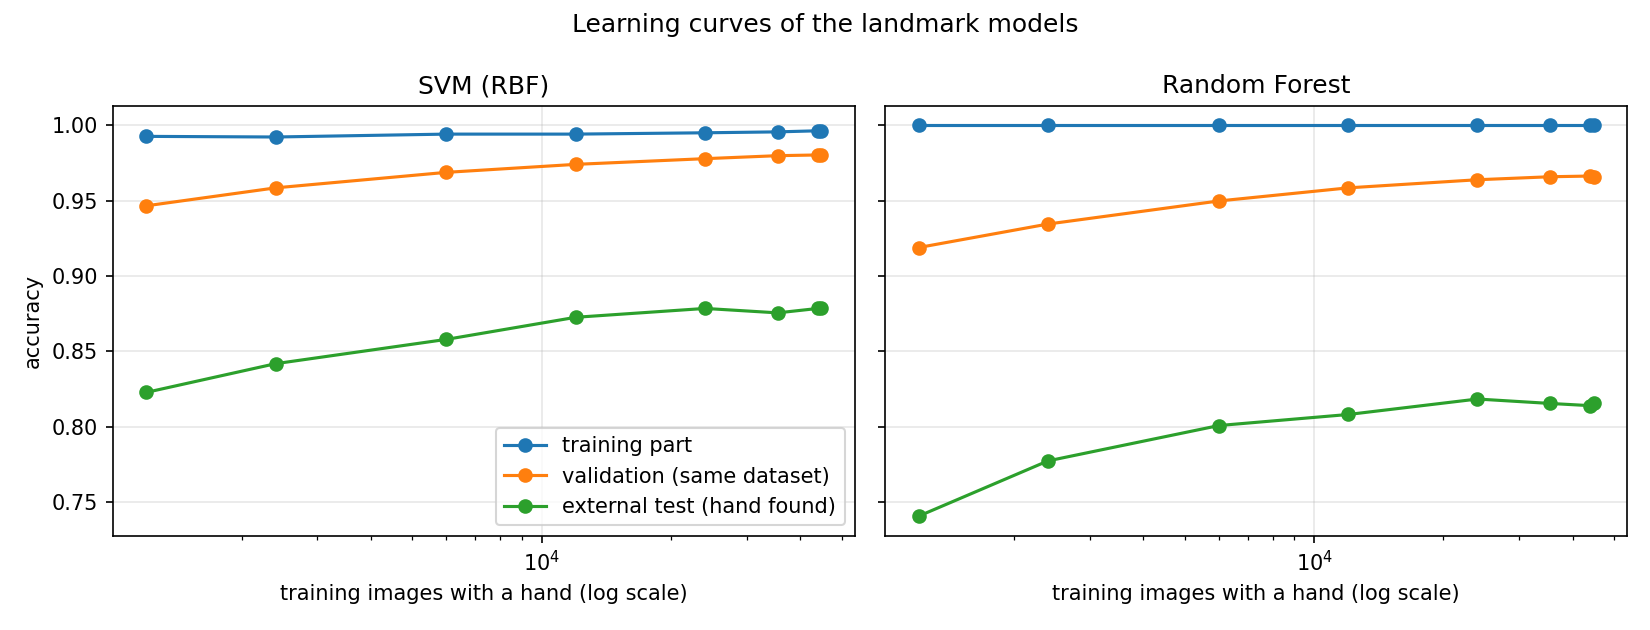

,model,per_class,n_train,train_acc,val_acc,test_acc_hand_found,seconds
0,SVM (RBF),50,1200,0.992,0.946,0.823,0.7
1,Random Forest,50,1200,1.000,0.919,0.741,0.7
2,SVM (RBF),100,2400,0.992,0.958,0.842,1.1
3,Random Forest,100,2400,1.000,0.934,0.777,0.9
4,SVM (RBF),250,6000,0.994,0.969,0.858,2.4
5,Random Forest,250,6000,1.000,0.950,0.801,1.7
6,SVM (RBF),500,12000,0.994,0.974,0.873,4.7
7,Random Forest,500,12000,1.000,0.958,0.808,3.3
8,SVM (RBF),1000,24000,0.995,0.978,0.878,10.6
9,Random Forest,1000,24000,1.000,0.964,0.818,8.6


In [10]:
show("figures/learning_curve_landmarks.png")
pd.read_csv("figures/learning_curve_landmarks.csv").round(3)

### MobileNetV2 Training History (Loss and Accuracy)
MobileNetV2 starts from ImageNet weights. The first 2 epochs train only the last layer (left of
the dashed line), then 8 epochs train the whole network (AdamW, cosine learning rate, label
smoothing 0.1). One model sees a square around the hand, the other the whole image.

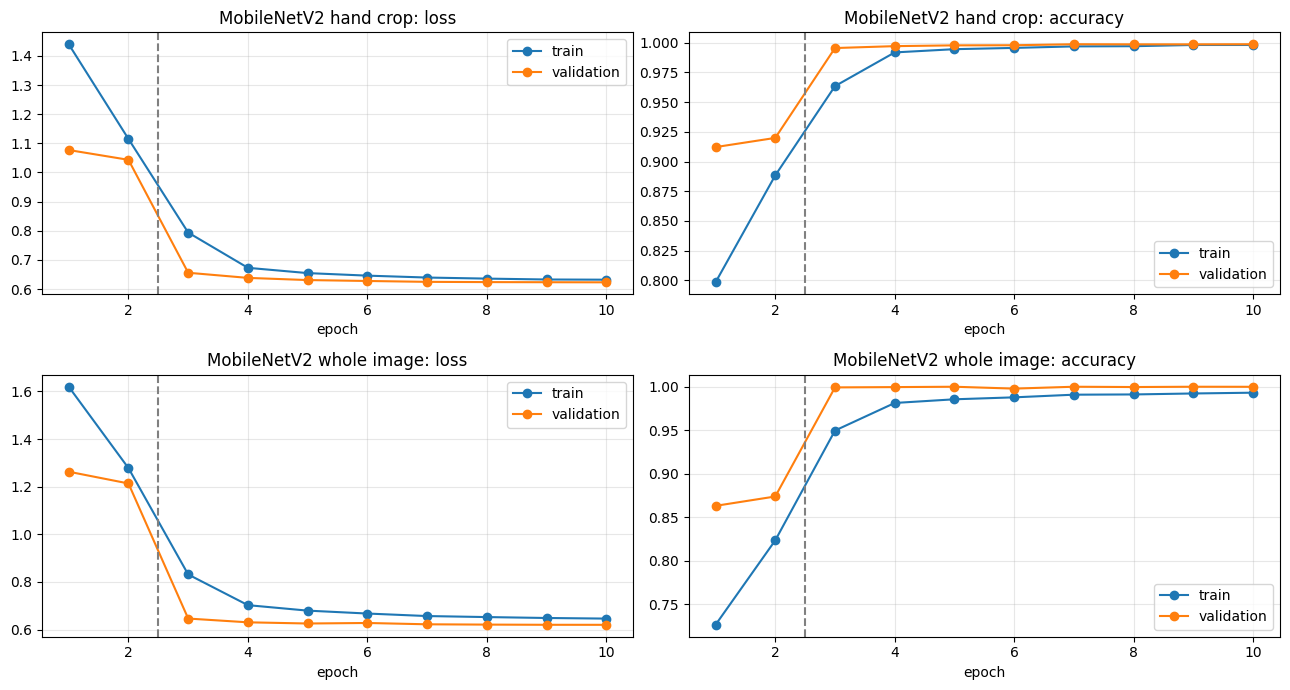

,epoch,head_epochs,train_loss,train_acc,val_loss,val_acc,val_f1,saved
0,1,2,1.4400,0.7982,1.0771,0.9121,0.9090,1
1,2,2,1.1151,0.8883,1.0435,0.9199,0.9178,1
2,3,2,0.7938,0.9635,0.6560,0.9956,0.9945,1
3,4,2,0.6729,0.9919,0.6384,0.9972,0.9967,1
4,5,2,0.6549,0.9946,0.6310,0.9978,0.9975,1
5,6,2,0.6461,0.9957,0.6278,0.9979,0.9976,1
6,7,2,0.6396,0.9970,0.6248,0.9988,0.9987,1
7,8,2,0.6359,0.9971,0.6240,0.9987,0.9986,0
8,9,2,0.6329,0.9981,0.6235,0.9987,0.9986,0
9,10,2,0.6322,0.9981,0.6232,0.9988,0.9987,1


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for row, (stem, name) in enumerate([("mobilenet_hand", "hand crop"), ("mobilenet", "whole image")]):
    h = pd.read_csv(f"figures/history_{stem}.csv")
    axes[row, 0].plot(h.epoch, h.train_loss, "o-", label="train"); axes[row, 0].plot(h.epoch, h.val_loss, "o-", label="validation")
    axes[row, 1].plot(h.epoch, h.train_acc, "o-", label="train"); axes[row, 1].plot(h.epoch, h.val_acc, "o-", label="validation")
    axes[row, 0].set_title(f"MobileNetV2 {name}: loss"); axes[row, 1].set_title(f"MobileNetV2 {name}: accuracy")
    for ax in axes[row]:
        ax.axvline(h.head_epochs[0] + 0.5, color="gray", ls="--"); ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()
pd.read_csv("figures/history_mobilenet_hand.csv").round(4)

### Testing MobileNetV2 (Hand Crop)
The saved best epoch is tested on the external test set.

In [12]:
!python train_mobilenet.py --crop-hand --eval-only --out mobilenet_hand.pt

Device: cuda  Train: 57600  Val: 14400  Test: 720 (hand found in 683)
,
,External test, all images        n=  720  accuracy=0.717  macro_f1=0.709
,External test, hand found        n=  683  accuracy=0.755  macro_f1=0.726
,
,Per-letter report (external test, all images):
,              precision    recall  f1-score   support
,
,           A       1.00      1.00      1.00        30
,           B       0.90      0.90      0.90        30
,           C       1.00      0.33      0.50        30
,           D       0.64      0.90      0.75        30
,           E       0.85      0.93      0.89        30
,           F       0.63      0.80      0.71        30
,           G       0.94      1.00      0.97        30
,           H       1.00      1.00      1.00        30
,           I       0.42      0.67      0.51        30
,           K       0.43      0.77      0.55        30
,           L       0.81      0.97      0.88        30
,           M       0.52      0.87      0.65        30
,           N

### Testing MobileNetV2 (Whole Image)
The same for the model that sees the whole image.

In [13]:
!python train_mobilenet.py --eval-only --out mobilenet.pt

Device: cuda  Train: 57600  Val: 14400  Test: 720 (hand found in 683)
,
,External test, all images        n=  720  accuracy=0.590  macro_f1=0.550
,External test, hand found        n=  683  accuracy=0.587  macro_f1=0.545
,
,Per-letter report (external test, all images):
,              precision    recall  f1-score   support
,
,           A       0.50      0.10      0.17        30
,           B       0.58      0.60      0.59        30
,           C       0.46      0.20      0.28        30
,           D       0.39      0.73      0.51        30
,           E       0.54      0.43      0.48        30
,           F       0.41      0.90      0.56        30
,           G       0.57      0.93      0.71        30
,           H       0.83      0.97      0.89        30
,           I       0.56      0.80      0.66        30
,           K       0.42      0.90      0.57        30
,           L       0.85      0.97      0.91        30
,           M       0.64      0.53      0.58        30
,           N

### Testing the Ready ViT Model
`dima806/asl_alphabet_image_detection` is a Vision Transformer from Hugging Face that its author
trained on the ASL Alphabet dataset. We do not train it, we only use its 24 letter outputs.

In [14]:
!python evaluate_vit.py

Device: cuda  Test: 720 (hand found in 683)
,
,External test, all images        n=  720  accuracy=0.796  macro_f1=0.782
,External test, hand found        n=  683  accuracy=0.795  macro_f1=0.782
,
,Per-letter report (external test, all images):
,              precision    recall  f1-score   support
,
,           A       0.81      0.97      0.88        30
,           B       1.00      1.00      1.00        30
,           C       1.00      0.53      0.70        30
,           D       0.94      1.00      0.97        30
,           E       0.78      0.70      0.74        30
,           F       0.94      1.00      0.97        30
,           G       0.88      0.93      0.90        30
,           H       0.85      0.97      0.91        30
,           I       0.68      0.93      0.79        30
,           K       0.54      1.00      0.70        30
,           L       0.69      0.97      0.81        30
,           M       0.62      0.97      0.75        30
,           N       0.91      0.33     


,Loading weights: 100%|##########| 200/200 [00:00<00:00, 655.15it/s]


### Evaluating All Letter Models
`evaluate_all.py` reads the saved predictions of all five models on the same 720 test images.
A model that gives no answer (no hand found) counts as a mistake.

In [15]:
!python evaluate_all.py

# Letter results (generated by evaluate_all.py)
,
,External test set: 720 images, MediaPipe finds a hand in 683. A model with no answer (no hand) counts as a mistake in the 'all' columns.
,
,## Main results (external test)
,
,| Model | Accuracy, all 720 | 95% CI (bootstrap) | Accuracy, hand found (683) | Macro precision, all | Macro recall, all | Macro F1, all 720 | Macro F1, hand found | Images answered |
,|---|---|---|---|---|---|---|---|---|
,| SVM | 83.3% (600) | 80.6% to 85.8% | 87.8% | 0.890 | 0.833 | 0.848 | 0.871 | 683 |
,| Random Forest | 77.4% (557) | 74.3% to 80.4% | 81.6% | 0.847 | 0.774 | 0.784 | 0.807 | 683 |
,| ViT (ready model) | 79.6% (573) | 76.7% to 82.5% | 79.5% | 0.837 | 0.796 | 0.782 | 0.782 | 720 |
,| MobileNetV2, hand crop | 71.7% (516) | 68.3% to 74.9% | 75.5% | 0.778 | 0.717 | 0.709 | 0.726 | 683 |
,| MobileNetV2, whole image | 59.0% (425) | 55.4% to 62.5% | 58.7% | 0.682 | 0.590 | 0.550 | 0.545 | 720 |
,
,## McNemar test (exact, two-sided)
,
,| Model A | Mode

### Letter Results
Accuracy with a 95% bootstrap interval, and macro precision, recall and F1.



| Model | Accuracy, all 720 | 95% CI (bootstrap) | Accuracy, hand found (683) | Macro precision, all | Macro recall, all | Macro F1, all 720 | Macro F1, hand found | Images answered |
|---|---|---|---|---|---|---|---|---|
| SVM | 83.3% (600) | 80.6% to 85.8% | 87.8% | 0.890 | 0.833 | 0.848 | 0.871 | 683 |
| Random Forest | 77.4% (557) | 74.3% to 80.4% | 81.6% | 0.847 | 0.774 | 0.784 | 0.807 | 683 |
| ViT (ready model) | 79.6% (573) | 76.7% to 82.5% | 79.5% | 0.837 | 0.796 | 0.782 | 0.782 | 720 |
| MobileNetV2, hand crop | 71.7% (516) | 68.3% to 74.9% | 75.5% | 0.778 | 0.717 | 0.709 | 0.726 | 683 |
| MobileNetV2, whole image | 59.0% (425) | 55.4% to 62.5% | 58.7% | 0.682 | 0.590 | 0.550 | 0.545 | 720 |


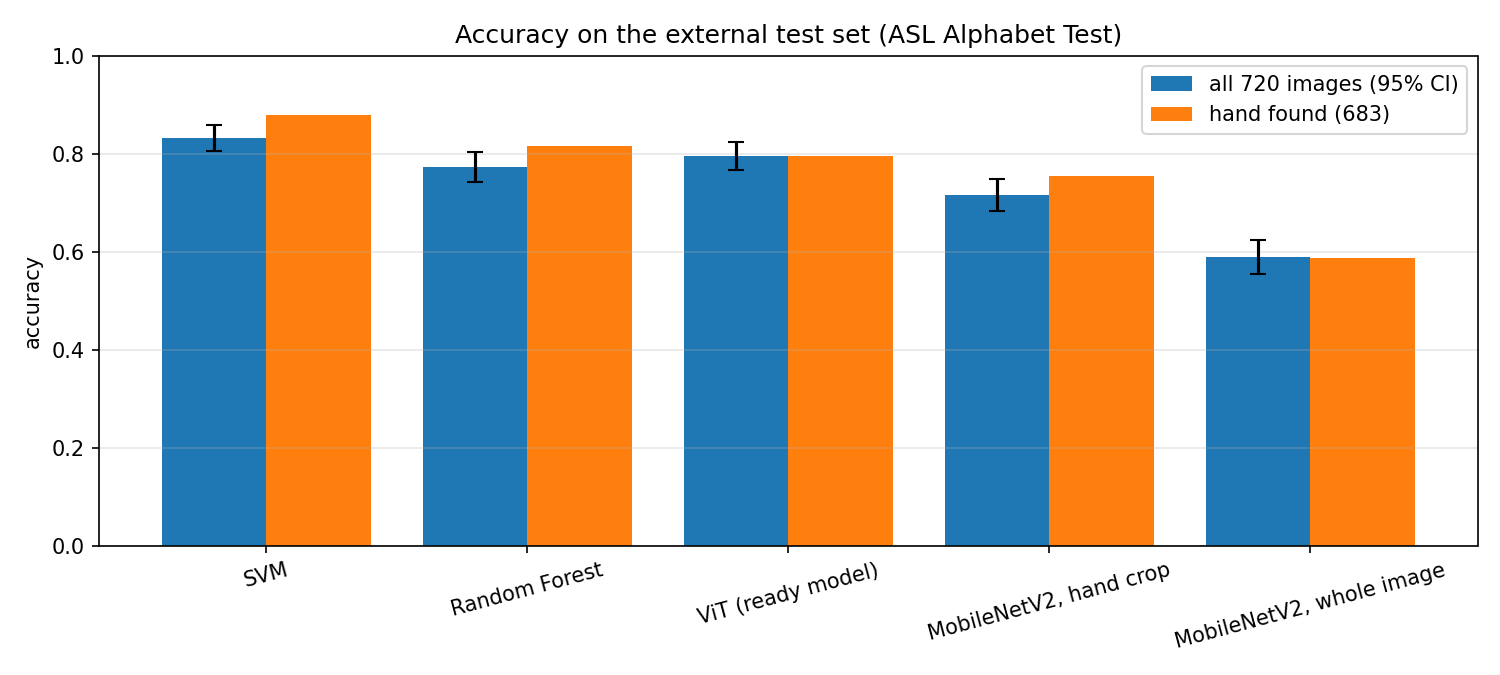

In [16]:
section("figures/metrics.md", "Main results (external test)")
show("figures/model_comparison.png", 800)

### Statistical Significance (McNemar Test)
The exact McNemar test compares two models on the same images. A p-value below 0.05 means the
difference is probably not random.

In [17]:
section("figures/metrics.md", "McNemar test (exact, two-sided)")



| Model A | Model B | Images | Only A right | Only B right | p-value |
|---|---|---|---|---|---|
| SVM | Random Forest | all 720 | 62 | 19 | < 0.0001 |
| SVM | Random Forest | hand found | 62 | 19 | < 0.0001 |
| SVM | ViT (ready model) | all 720 | 94 | 67 | 0.04 |
| SVM | ViT (ready model) | hand found | 94 | 37 | < 0.0001 |
| SVM | MobileNetV2, hand crop | all 720 | 115 | 31 | < 0.0001 |
| SVM | MobileNetV2, hand crop | hand found | 115 | 31 | < 0.0001 |
| SVM | MobileNetV2, whole image | all 720 | 225 | 50 | < 0.0001 |
| SVM | MobileNetV2, whole image | hand found | 225 | 26 | < 0.0001 |
| Random Forest | ViT (ready model) | all 720 | 80 | 96 | 0.26 |
| Random Forest | ViT (ready model) | hand found | 80 | 66 | 0.28 |
| Random Forest | MobileNetV2, hand crop | all 720 | 94 | 53 | 0.0009 |
| Random Forest | MobileNetV2, hand crop | hand found | 94 | 53 | 0.0009 |
| Random Forest | MobileNetV2, whole image | all 720 | 197 | 65 | < 0.0001 |
| Random Forest | MobileNetV2, whole image | hand found | 197 | 41 | < 0.0001 |
| ViT (ready model) | MobileNetV2, hand crop | all 720 | 102 | 45 | < 0.0001 |
| ViT (ready model) | MobileNetV2, hand crop | hand found | 72 | 45 | 0.02 |
| ViT (ready model) | MobileNetV2, whole image | all 720 | 187 | 39 | < 0.0001 |
| ViT (ready model) | MobileNetV2, whole image | hand found | 177 | 35 | < 0.0001 |
| MobileNetV2, hand crop | MobileNetV2, whole image | all 720 | 143 | 52 | < 0.0001 |
| MobileNetV2, hand crop | MobileNetV2, whole image | hand found | 143 | 28 | < 0.0001 |


### F1-score for Each Letter and Common Mistakes
The F1-score of every letter shows which signs are hard. The second table lists the five most common mistakes of each model.

In [18]:
section("figures/metrics.md", "F1 for each letter (external test, all 720 images)")
section("figures/metrics.md", "Most common mistakes (true letter as predicted, count of 30)")



| Class | SVM | Random Forest | ViT (ready model) | MobileNetV2, hand crop | MobileNetV2, whole image |
|---|---|---|---|---|---|
| A | 1.00 | 0.97 | 0.88 | 1.00 | 0.17 |
| B | 0.97 | 0.97 | 1.00 | 0.90 | 0.59 |
| C | 0.58 | 0.48 | 0.70 | 0.50 | 0.28 |
| D | 0.86 | 0.65 | 0.97 | 0.75 | 0.51 |
| E | 0.90 | 0.83 | 0.74 | 0.89 | 0.48 |
| F | 1.00 | 1.00 | 0.97 | 0.71 | 0.56 |
| G | 0.78 | 0.91 | 0.90 | 0.97 | 0.71 |
| H | 0.88 | 0.92 | 0.91 | 1.00 | 0.89 |
| I | 0.78 | 0.78 | 0.79 | 0.51 | 0.66 |
| K | 0.84 | 0.83 | 0.70 | 0.55 | 0.57 |
| L | 0.94 | 0.91 | 0.81 | 0.88 | 0.91 |
| M | 0.62 | 0.55 | 0.75 | 0.65 | 0.58 |
| N | 0.43 | 0.39 | 0.49 | 0.27 | 0.46 |
| O | 0.67 | 0.43 | 0.94 | 0.75 | 0.24 |
| P | 0.95 | 0.97 | 0.87 | 0.92 | 0.94 |
| Q | 0.93 | 0.95 | 0.82 | 0.91 | 0.93 |
| R | 0.89 | 0.67 | 0.66 | 0.67 | 0.60 |
| S | 0.78 | 0.91 | 0.67 | 0.42 | 0.12 |
| T | 0.87 | 0.57 | 0.45 | 0.64 | 0.45 |
| U | 0.94 | 0.56 | 0.85 | 0.85 | 0.52 |
| V | 0.85 | 0.75 | 0.50 | 0.00 | 0.12 |
| W | 0.98 | 0.92 | 0.94 | 0.81 | 0.58 |
| X | 0.92 | 0.91 | 0.63 | 0.54 | 0.49 |
| Y | 1.00 | 1.00 | 0.86 | 0.95 | 0.83 |




| Model | 1st | 2nd | 3rd | 4th | 5th |
|---|---|---|---|---|---|
| SVM | N as M (18) | C as O (12) | I as no answer (10) | S as E (7) | O as no answer (5) |
| Random Forest | N as M (20) | O as D (14) | R as U (12) | C as D (12) | T as E (11) |
| ViT (ready model) | N as M (18) | V as K (16) | T as X (12) | Q as P (9) | R as K (8) |
| MobileNetV2, hand crop | N as M (23) | V as K (23) | S as I (16) | X as R (12) | I as no answer (10) |
| MobileNetV2, whole image | V as K (22) | O as D (21) | A as W (14) | S as I (13) | R as K (9) |


### Confusion Matrix
Confusion matrices of the best landmark model, the ready ViT and MobileNetV2 on the external test.

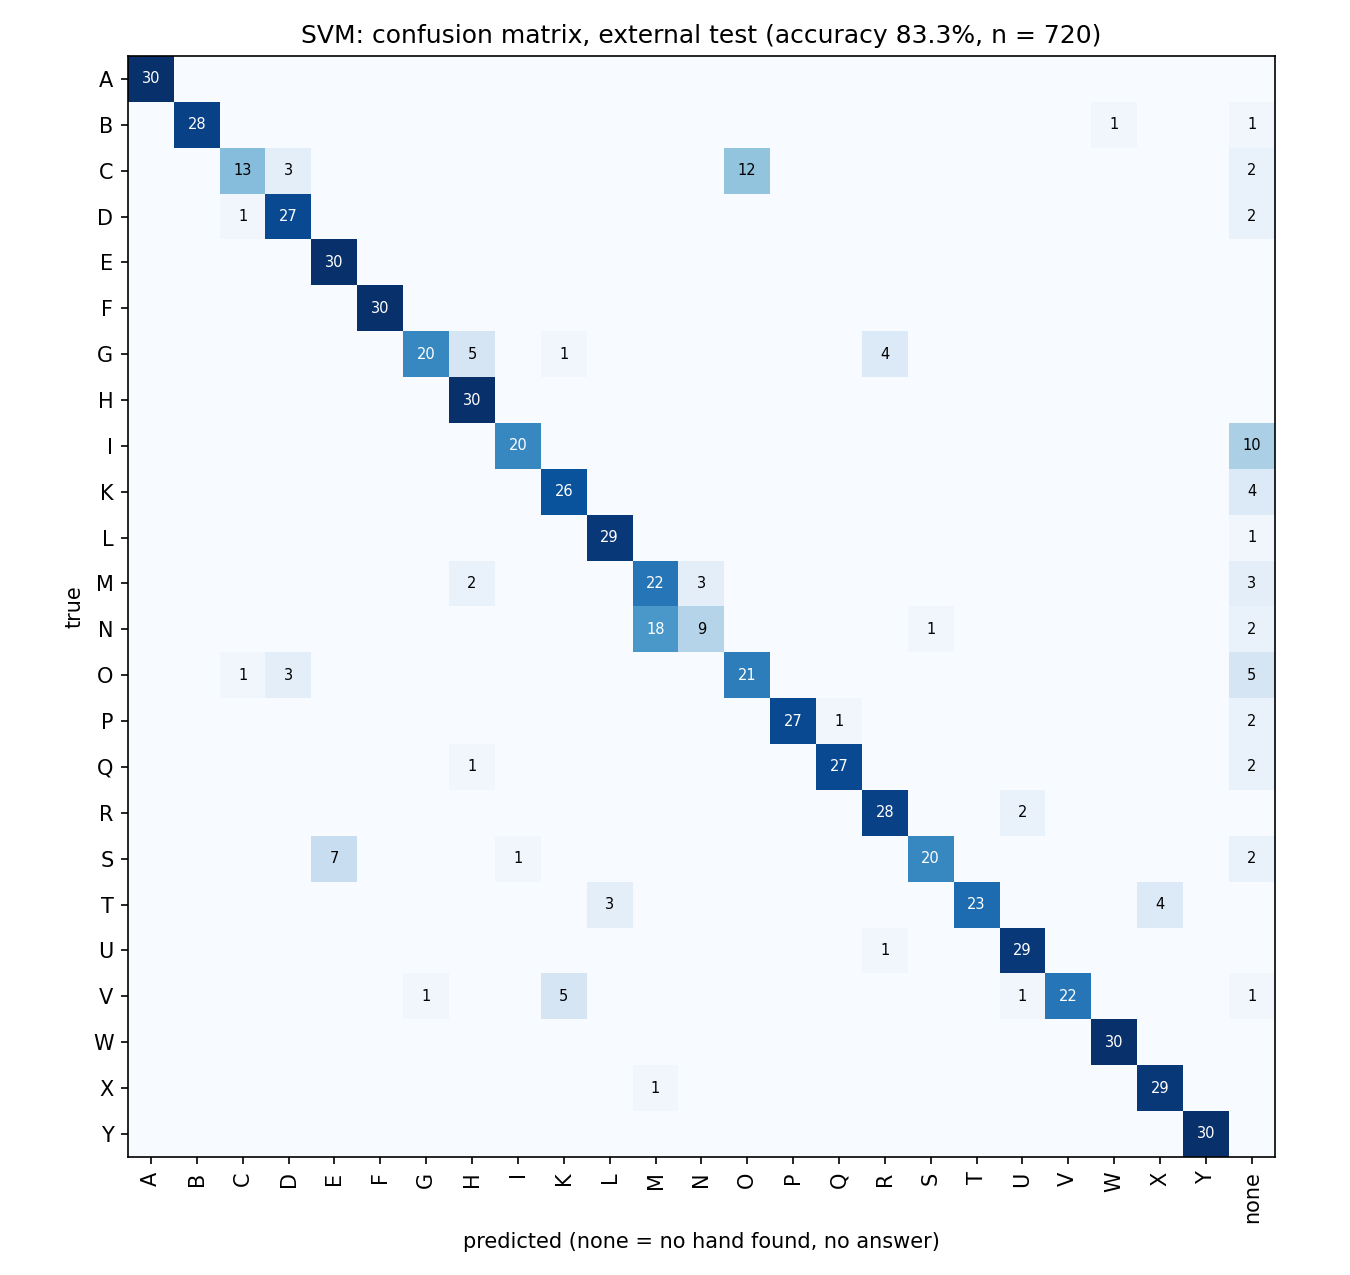

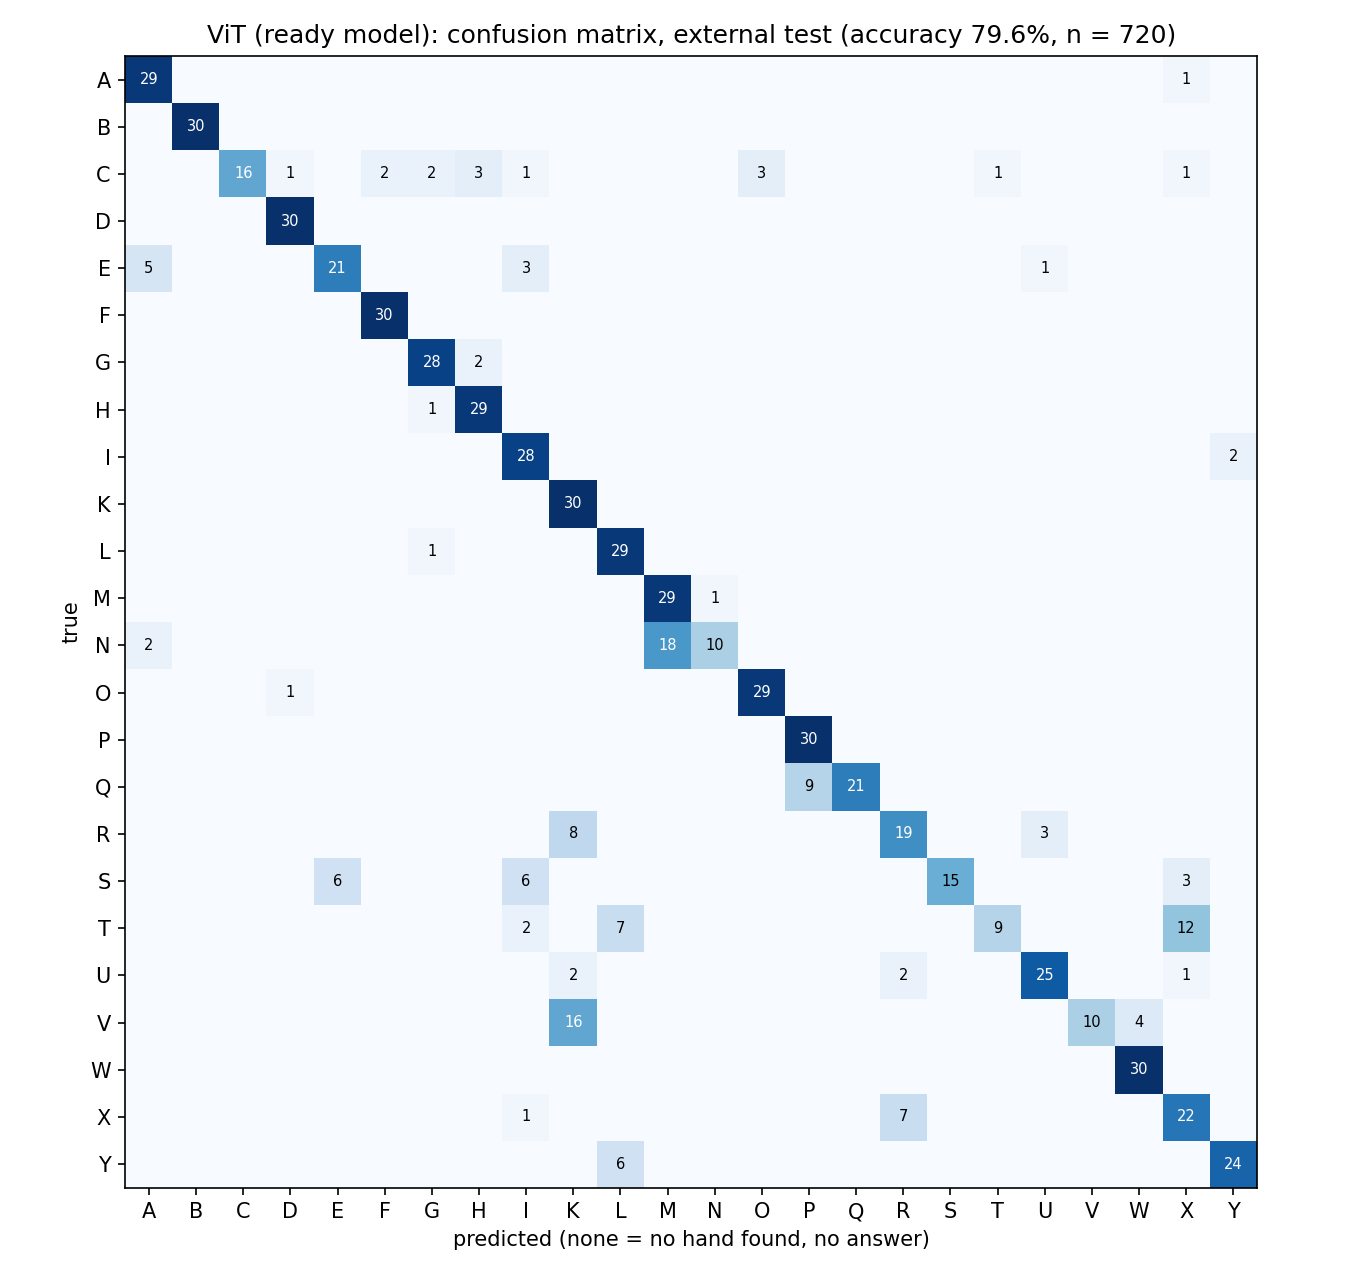

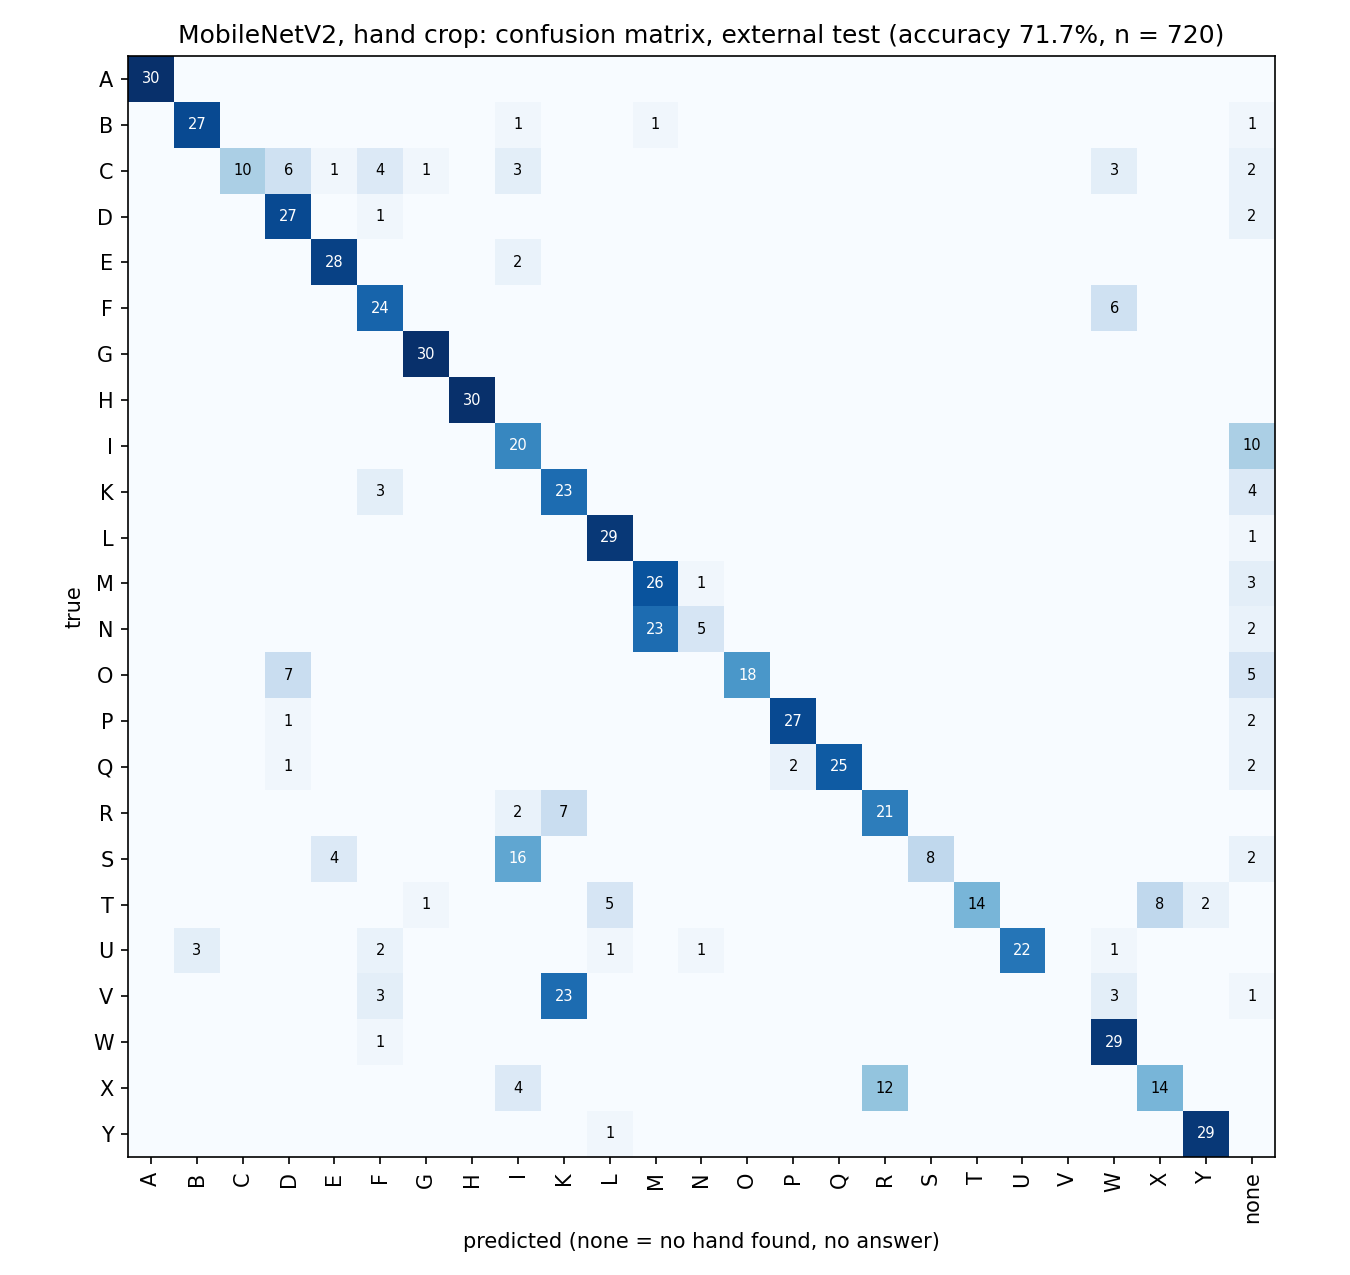

In [19]:
for name in ["svm", "vit", "mobilenet_hand"]:
    show(f"figures/confusion_{name}.png", 650)

### Testing the Letter Model on Example Images
The saved SVM model predicts some external test images.

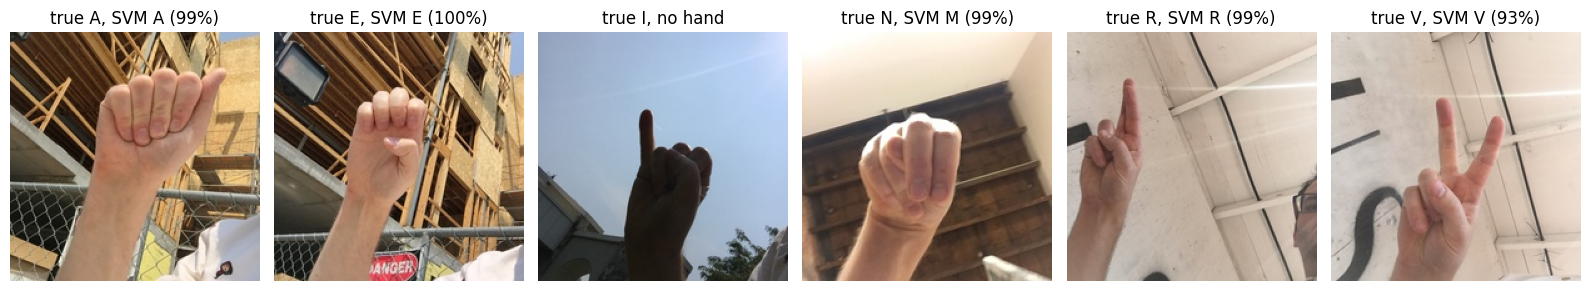

In [20]:
svm = joblib.load("svm.joblib")
fig, axes = plt.subplots(1, 6, figsize=(16, 3.4))
for ax, (path, letter) in zip(axes, test[5::121]):
    rgb = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
    points, side = detect(detector, rgb)
    if points is None:
        title = f"true {letter}, no hand"
    else:
        probs = svm.predict_proba([normalize(points, side)])[0]
        title = f"true {letter}, SVM {svm.classes_[probs.argmax()]} ({probs.max():.0%})"
    ax.imshow(rgb); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

# Part 2. Words with Movement

### Loading the Word Dataset
The Kaggle ISLR dataset has 94,477 short videos of 250 ASL signs by 21 people, given as MediaPipe
landmarks for every frame. We chose 25 everyday words (`words.py`) and kept only the hands and
the pose of their clips (`islr_prepare.py`).

25 words: hello, bye, thankyou, please, yes, no, drink, water, food, hungry, sleep, happy, sad, mad, mom, dad, home, go, wait, look, finish, like, where, why, tomorrow
,Clips: 9596 | people: 21


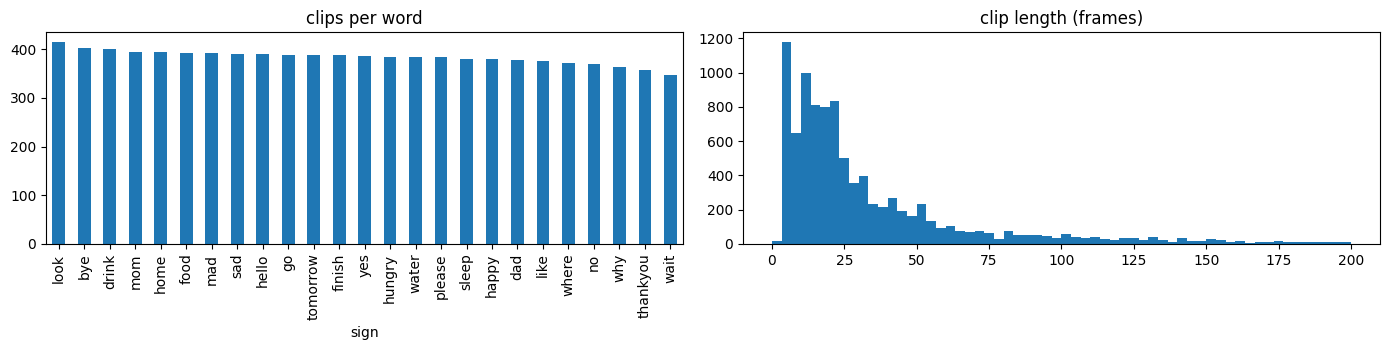

Median clip length: 21 frames


In [21]:
from words import WORDS
clips = pd.read_csv("data/islr/clips.csv")
print(len(WORDS), "words:", ", ".join(WORDS))
print("Clips:", len(clips), "| people:", clips.participant_id.nunique())
lengths = [len(np.load(f"data/islr/clips/{s}.npy", mmap_mode="r")) for s in clips.sequence_id]
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
clips.sign.value_counts().plot.bar(ax=axes[0], title="clips per word")
axes[1].hist(lengths, bins=60, range=(0, 200)); axes[1].set_title("clip length (frames)")
plt.tight_layout(); plt.show()
print("Median clip length:", int(np.median(lengths)), "frames")

### Splitting the Dataset by Person
The clips are split by person: 14 people for training, 3 for validation and 4 for the test.
So the test shows how the models work for people they have never seen.

In [22]:
from train_islr import split_people
test_p, val_p, train_p = split_people(clips.participant_id.unique())
part = clips.participant_id.map(lambda p: "test" if p in test_p else "validation" if p in val_p else "train")
pd.DataFrame({"people": clips.groupby(part).participant_id.nunique(), "clips": part.value_counts()})

,people,clips
participant_id,,
test,4,1825
train,14,6417
validation,3,1354


### Features of a Word Clip
For each frame we keep both hands (wrist position, hand shape, "hand seen" flag) and 7 upper body
points, measured from the middle of the shoulders in shoulder widths. Left-handed signs are
mirrored and every clip is resampled to 32 steps (`word_features.py`). Below: one clip of
"hello" and the 32 x 104 sequence that the networks get.

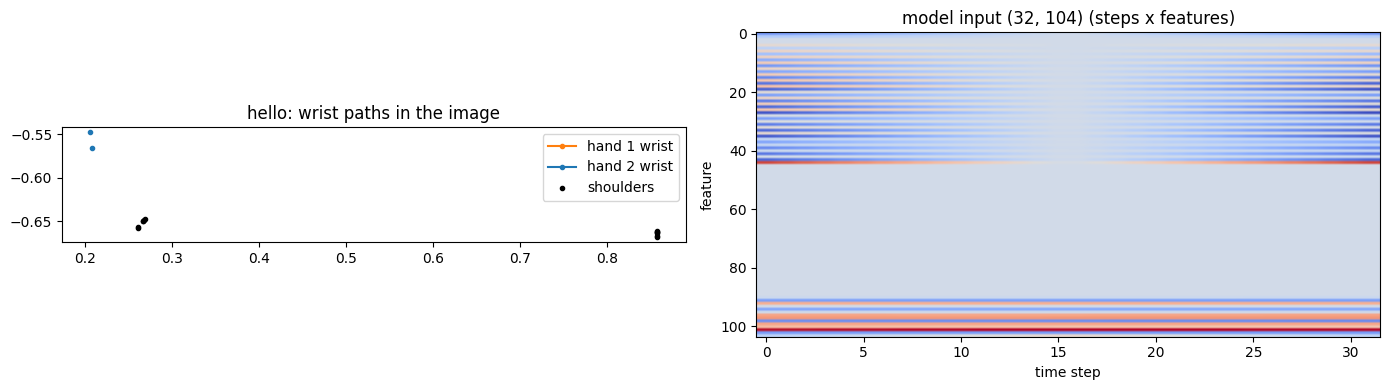

In [23]:
from word_features import sequence
sid = clips[clips.sign == "hello"].sequence_id.iloc[3]
clip = np.load(f"data/islr/clips/{sid}.npy").astype(np.float32)
seq = sequence(clip)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for start, color, name in ((0, "tab:orange", "hand 1"), (21, "tab:blue", "hand 2")):
    axes[0].plot(clip[:, start, 0], -clip[:, start, 1], ".-", color=color, label=name + " wrist")
axes[0].plot(clip[:, 42 + 11, 0], -clip[:, 42 + 11, 1], "k.", label="shoulders")
axes[0].plot(clip[:, 42 + 12, 0], -clip[:, 42 + 12, 1], "k.")
axes[0].set_title("hello: wrist paths in the image"); axes[0].legend(); axes[0].set_aspect("equal")
axes[1].imshow(seq.T, aspect="auto", cmap="coolwarm"); axes[1].set_title(f"model input {seq.shape} (steps x features)")
axes[1].set_xlabel("time step"); axes[1].set_ylabel("feature")
plt.tight_layout(); plt.show()

### Training the Word Models
SVM and Random Forest get a summary of the clip (1,040 numbers). The 1D-CNN and the GRU get the
whole 32 x 104 sequence and are trained for 80 epochs with random augmentation (AdamW, one-cycle
learning rate, label smoothing 0.1). The epoch with the best validation accuracy is kept.

In [24]:
!python train_islr.py

Clips: train 6207 (14 people), validation 1310 (3 people), test 1753 (4 people)
,Test people: [30680, 37779, 49445, 62590]
,SVM            validation accuracy 0.744 (275 s)
,SVM            test accuracy 0.754  macro F1 0.747
,Random Forest  validation accuracy 0.698 (34 s)
,Random Forest  test accuracy 0.732  macro F1 0.722
,  1D-CNN epoch 1: train loss 2.641 acc 0.305  val loss 2.401 acc 0.516
,  1D-CNN epoch 10: train loss 1.113 acc 0.842  val loss 1.373 acc 0.766
,  1D-CNN epoch 20: train loss 0.902 acc 0.922  val loss 1.308 acc 0.785
,  1D-CNN epoch 30: train loss 0.812 acc 0.955  val loss 1.121 acc 0.864
,  1D-CNN epoch 40: train loss 0.751 acc 0.978  val loss 1.135 acc 0.856
,  1D-CNN epoch 50: train loss 0.715 acc 0.990  val loss 1.141 acc 0.855
,  1D-CNN epoch 60: train loss 0.695 acc 0.994  val loss 1.118 acc 0.879
,  1D-CNN epoch 70: train loss 0.683 acc 0.996  val loss 1.135 acc 0.873
,  1D-CNN epoch 80: train loss 0.679 acc 0.997  val loss 1.145 acc 0.861
,1D-CNN         be

### Word Models Training History (Loss and Accuracy)
Loss and accuracy of the 1D-CNN and the GRU for each of the 80 epochs, on the training and the validation people.

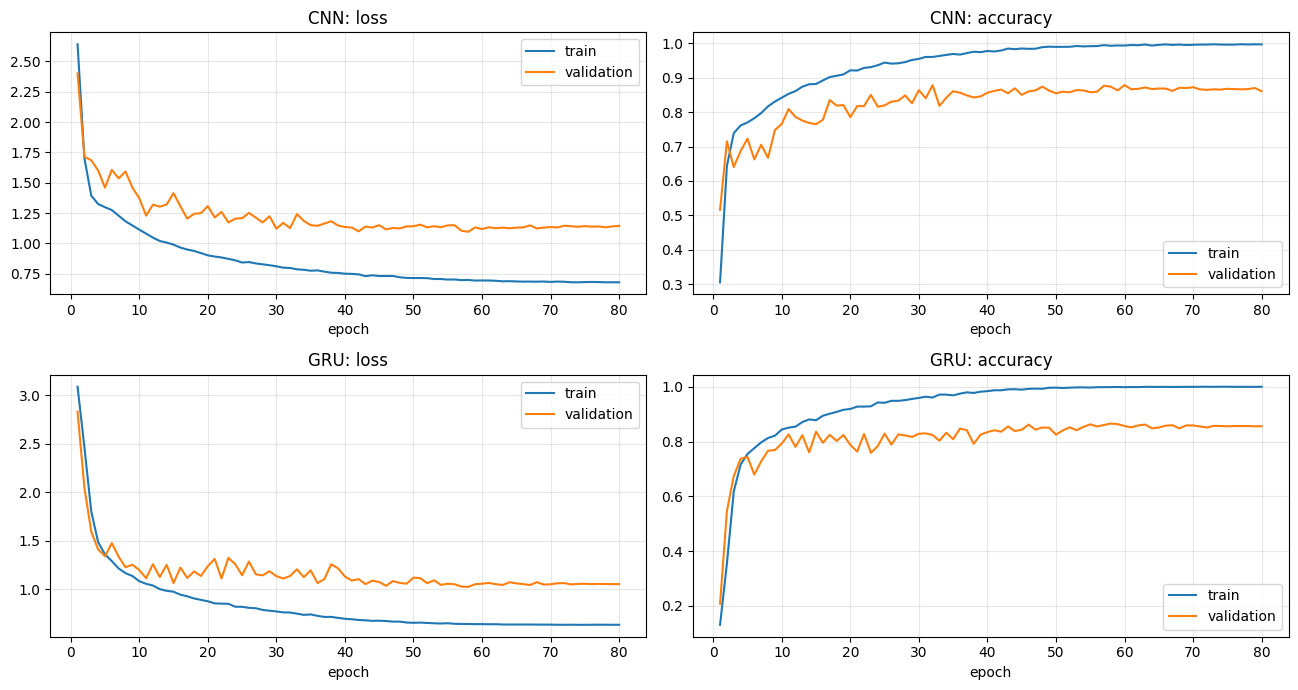

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for row, key in enumerate(["cnn", "gru"]):
    h = pd.read_csv(f"figures/history_words_{key}.csv")
    axes[row, 0].plot(h.epoch, h.train_loss, label="train"); axes[row, 0].plot(h.epoch, h.val_loss, label="validation")
    axes[row, 1].plot(h.epoch, h.train_acc, label="train"); axes[row, 1].plot(h.epoch, h.val_acc, label="validation")
    axes[row, 0].set_title(f"{key.upper()}: loss"); axes[row, 1].set_title(f"{key.upper()}: accuracy")
    for ax in axes[row]:
        ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

### Evaluating All Word Models
The saved predictions of the four models on the clips of the 4 test people.

In [26]:
!python evaluate_all.py --task words

# Word results (generated by evaluate_all.py --task words)
,
,Test set: 1753 clips of 25 words by 4 people that the models never saw in training (Kaggle ISLR).
,
,## Main results (test people)
,
,| Model | Accuracy (1753 clips) | 95% CI (bootstrap) | Macro precision | Macro recall | Macro F1 |
,|---|---|---|---|---|---|
,| SVM | 75.4% (1321) | 73.4% to 77.4% | 0.764 | 0.747 | 0.747 |
,| Random Forest | 73.2% (1283) | 71.1% to 75.2% | 0.735 | 0.725 | 0.722 |
,| 1D-CNN | 83.3% (1460) | 81.5% to 85.0% | 0.842 | 0.829 | 0.831 |
,| GRU | 85.9% (1505) | 84.1% to 87.4% | 0.862 | 0.854 | 0.855 |
,
,## Accuracy for each test person
,
,| Model | person 30680 (350 clips) | person 37779 (456 clips) | person 49445 (491 clips) | person 62590 (456 clips) |
,|---|---|---|---|---|
,| SVM | 59.7% | 92.3% | 59.3% | 87.7% |
,| Random Forest | 62.0% | 84.6% | 56.8% | 87.9% |
,| 1D-CNN | 72.9% | 88.8% | 77.0% | 92.5% |
,| GRU | 68.9% | 93.6% | 81.9% | 95.4% |
,
,## McNemar test (exact, two-sided)
,
,| Model

### Word Results
Accuracy with a 95% bootstrap interval on all test clips, and the accuracy for each of the 4 test people.



| Model | Accuracy (1753 clips) | 95% CI (bootstrap) | Macro precision | Macro recall | Macro F1 |
|---|---|---|---|---|---|
| SVM | 75.4% (1321) | 73.4% to 77.4% | 0.764 | 0.747 | 0.747 |
| Random Forest | 73.2% (1283) | 71.1% to 75.2% | 0.735 | 0.725 | 0.722 |
| 1D-CNN | 83.3% (1460) | 81.5% to 85.0% | 0.842 | 0.829 | 0.831 |
| GRU | 85.9% (1505) | 84.1% to 87.4% | 0.862 | 0.854 | 0.855 |




| Model | person 30680 (350 clips) | person 37779 (456 clips) | person 49445 (491 clips) | person 62590 (456 clips) |
|---|---|---|---|---|
| SVM | 59.7% | 92.3% | 59.3% | 87.7% |
| Random Forest | 62.0% | 84.6% | 56.8% | 87.9% |
| 1D-CNN | 72.9% | 88.8% | 77.0% | 92.5% |
| GRU | 68.9% | 93.6% | 81.9% | 95.4% |


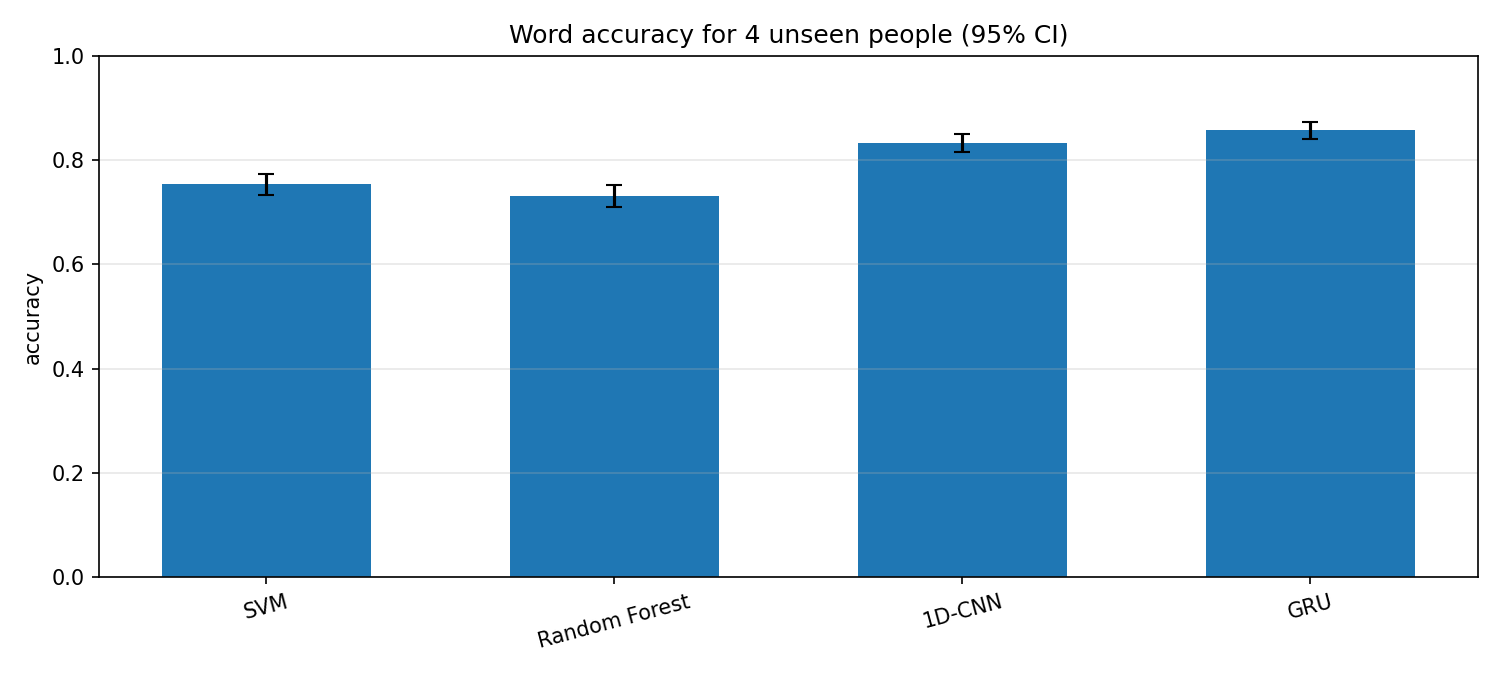

In [27]:
section("figures/words_metrics.md", "Main results (test people)")
section("figures/words_metrics.md", "Accuracy for each test person")
show("figures/words_model_comparison.png", 800)

### Statistical Significance (McNemar Test)
The same test as for the letters, now on the 1,753 test clips.

In [28]:
section("figures/words_metrics.md", "McNemar test (exact, two-sided)")



| Model A | Model B | Only A right | Only B right | p-value |
|---|---|---|---|---|
| SVM | Random Forest | 173 | 135 | 0.03 |
| SVM | 1D-CNN | 93 | 232 | < 0.0001 |
| SVM | GRU | 52 | 236 | < 0.0001 |
| Random Forest | 1D-CNN | 75 | 252 | < 0.0001 |
| Random Forest | GRU | 49 | 271 | < 0.0001 |
| 1D-CNN | GRU | 78 | 123 | 0.0018 |


### F1-score for Each Word and Common Mistakes
The F1-score of every word and the five most common mistakes of each model.

In [29]:
section("figures/words_metrics.md", "F1 for each word")
section("figures/words_metrics.md", "Most common mistakes (true word as predicted, count)")



| Class | SVM | Random Forest | 1D-CNN | GRU |
|---|---|---|---|---|
| hello | 0.73 | 0.71 | 0.89 | 0.89 |
| bye | 0.73 | 0.67 | 0.78 | 0.77 |
| thankyou | 0.74 | 0.69 | 0.86 | 0.86 |
| please | 0.86 | 0.77 | 0.85 | 0.88 |
| yes | 0.85 | 0.77 | 0.83 | 0.89 |
| no | 0.82 | 0.75 | 0.90 | 0.91 |
| drink | 0.78 | 0.73 | 0.81 | 0.91 |
| water | 0.82 | 0.91 | 0.94 | 0.94 |
| food | 0.80 | 0.76 | 0.85 | 0.88 |
| hungry | 0.73 | 0.72 | 0.84 | 0.83 |
| sleep | 0.61 | 0.66 | 0.66 | 0.78 |
| happy | 0.79 | 0.70 | 0.85 | 0.83 |
| sad | 0.65 | 0.70 | 0.85 | 0.87 |
| mad | 0.58 | 0.68 | 0.73 | 0.76 |
| mom | 0.74 | 0.71 | 0.79 | 0.86 |
| dad | 0.89 | 0.90 | 0.96 | 0.93 |
| home | 0.85 | 0.87 | 0.82 | 0.91 |
| go | 0.42 | 0.29 | 0.57 | 0.63 |
| wait | 0.62 | 0.67 | 0.86 | 0.81 |
| look | 0.76 | 0.75 | 0.90 | 0.92 |
| finish | 0.70 | 0.69 | 0.87 | 0.85 |
| like | 0.75 | 0.70 | 0.78 | 0.80 |
| where | 0.80 | 0.78 | 0.85 | 0.86 |
| why | 0.83 | 0.66 | 0.92 | 0.86 |
| tomorrow | 0.82 | 0.81 | 0.83 | 0.92 |




| Model | 1st | 2nd | 3rd | 4th | 5th |
|---|---|---|---|---|---|
| SVM | sad as sleep (15) | mad as sleep (13) | wait as sad (11) | where as go (10) | bye as hello (10) |
| Random Forest | drink as bye (11) | like as hungry (10) | finish as bye (10) | why as hello (10) | look as no (10) |
| 1D-CNN | sleep as mad (12) | finish as bye (9) | bye as drink (9) | sad as mad (7) | where as go (7) |
| GRU | finish as bye (11) | like as hungry (9) | wait as why (9) | happy as thankyou (9) | sad as sleep (8) |


### Confusion Matrix
Confusion matrix of the GRU on the test people.

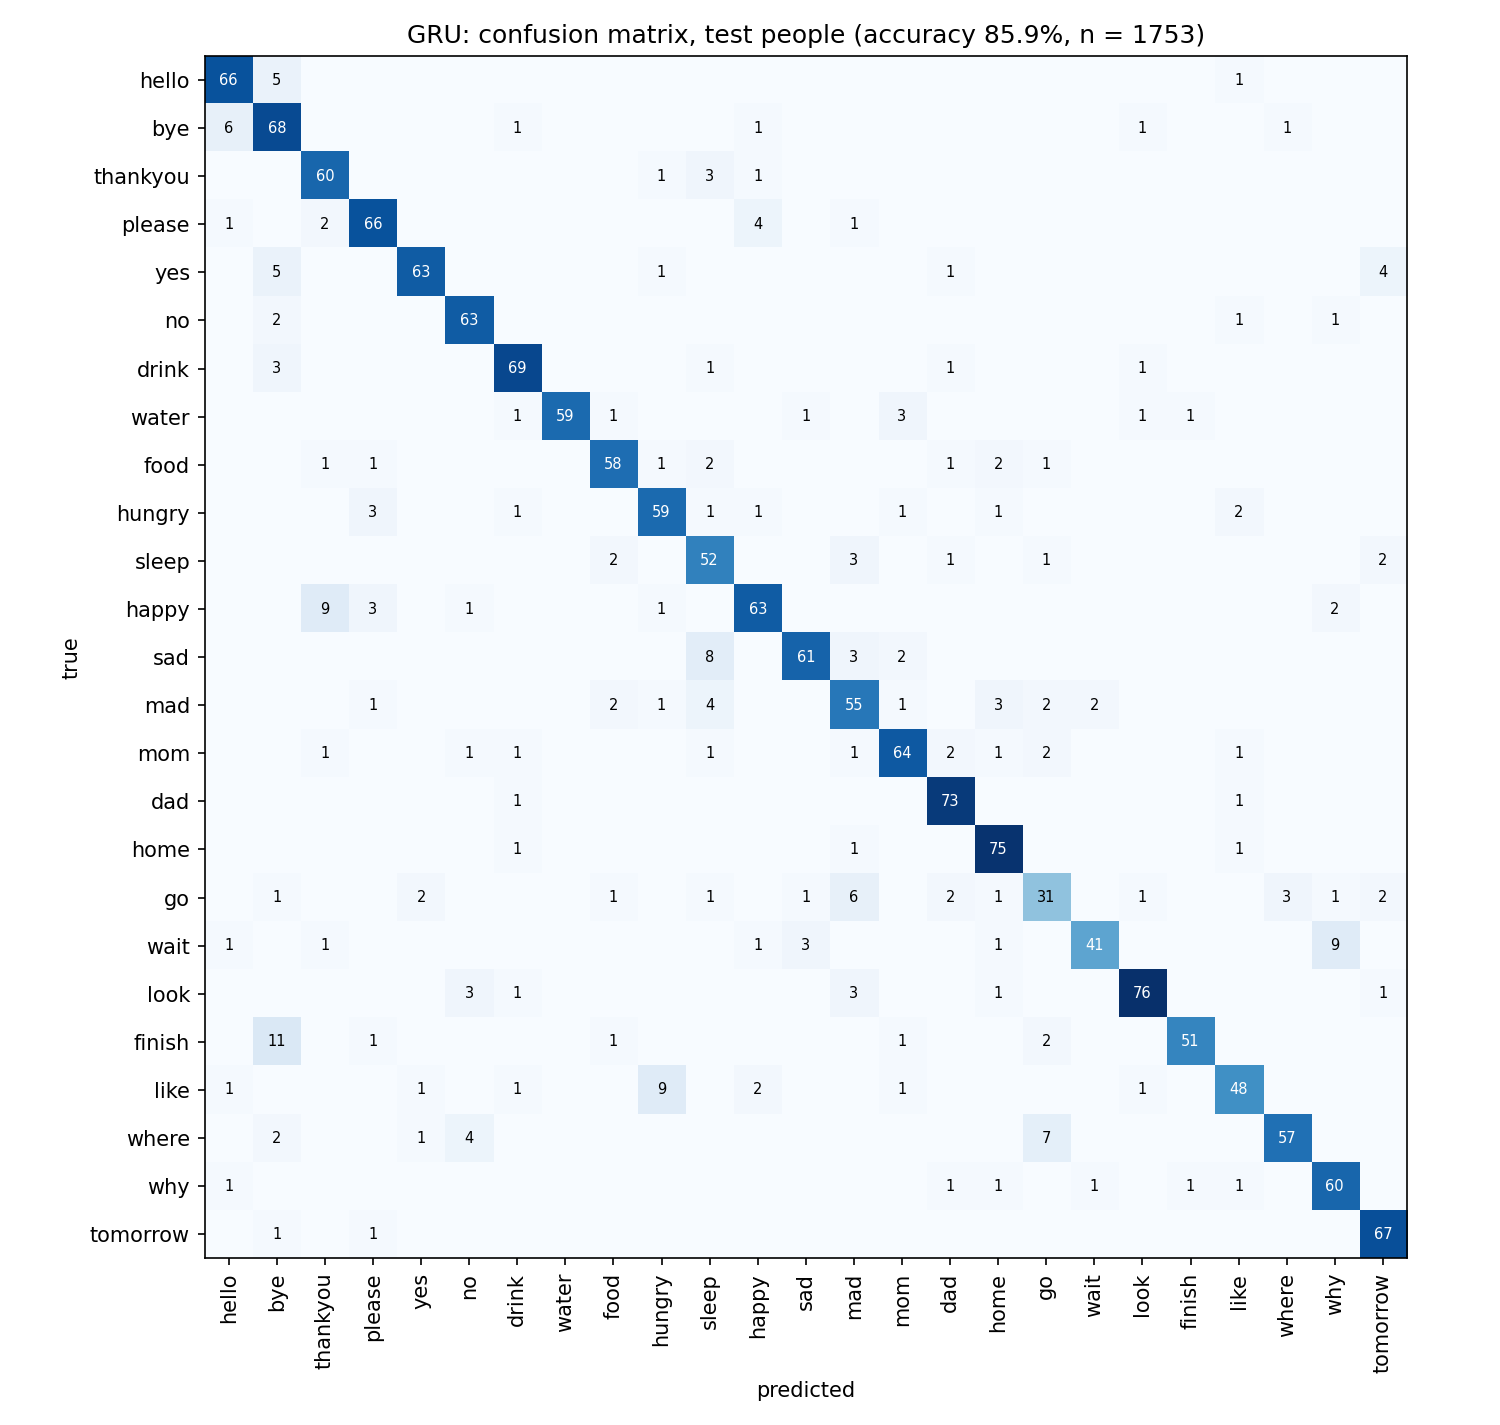

In [30]:
show("figures/words_confusion_gru.png", 750)

### Testing the Word Model on Example Clips
The model of the webcam application (`words_model.pt`, the best network on validation) gives its
3 best guesses for some clips of the test people.

In [31]:
from word_live import WordModel
word_model = WordModel()
examples = clips[clips.participant_id.isin(test_p)].sample(8, random_state=1)
rows = []
for sid, sign in zip(examples.sequence_id, examples.sign):
    top = word_model.top(np.load(f"data/islr/clips/{sid}.npy").astype(np.float32), aspect=1.2)
    rows.append({"true word": sign, "1st guess": f"{top[0][0]} ({top[0][1]:.0%})",
                 "2nd guess": f"{top[1][0]} ({top[1][1]:.0%})", "3rd guess": f"{top[2][0]} ({top[2][1]:.0%})"})
pd.DataFrame(rows)

,true word,1st guess,2nd guess,3rd guess
0,hello,hello (69%),why (8%),tomorrow (3%)
1,hello,hello (74%),why (3%),where (2%)
2,dad,dad (66%),no (7%),thankyou (3%)
3,where,where (65%),go (10%),no (3%)
4,wait,wait (86%),thankyou (1%),go (1%)
5,tomorrow,tomorrow (47%),mad (6%),why (6%)
6,mom,please (15%),hungry (15%),like (12%)
7,why,wait (45%),why (11%),finish (7%)


# Webcam Application
`webcam_demo.py` runs the models live on the webcam (`python webcam_demo.py`).

In letters mode the user shows a letter with one or both hands and holds it for about 1.5 s.
The SVM model recognizes it, and the letter is written on the screen and spoken.

In words mode (key M) the user makes a word and then lowers the hands or holds them still.
The word network then shows its 3 best guesses.

We also wrote `word_examples.py`. It plays a real clip of every word from the dataset as a
skeleton, so a user can see how the sign is made before trying it.

### Model Comparison
Test accuracy of all models, computed from the saved prediction files.

,task,model,accuracy,macro F1
0,letters (720 images),SVM,0.833,0.848
1,letters (720 images),Random Forest,0.774,0.784
2,letters (720 images),ViT (ready model),0.796,0.782
3,letters (720 images),"MobileNetV2, hand crop",0.717,0.709
4,letters (720 images),"MobileNetV2, whole image",0.590,0.550
5,"words (1,753 clips)",SVM,0.754,0.747
6,"words (1,753 clips)",Random Forest,0.732,0.722
7,"words (1,753 clips)",1D-CNN,0.833,0.831
8,"words (1,753 clips)",GRU,0.859,0.855


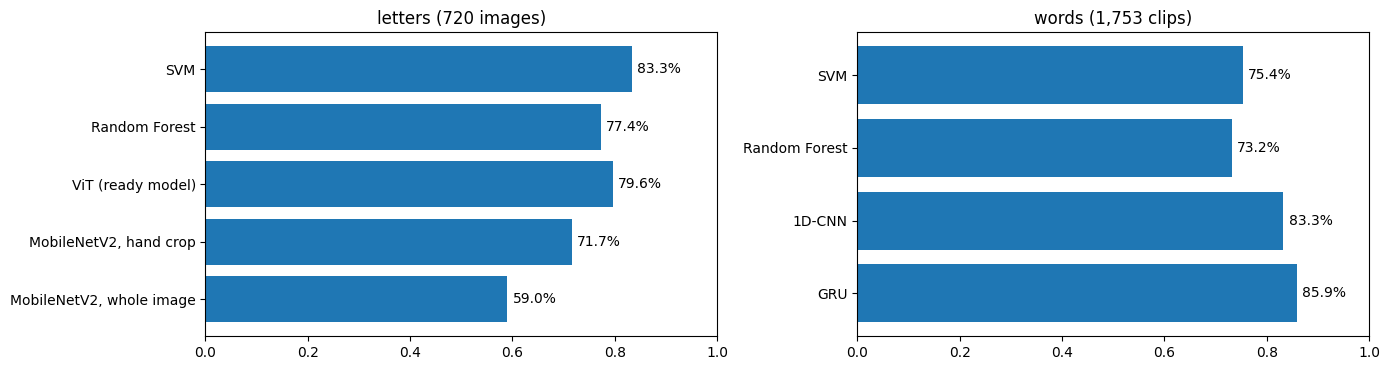

In [32]:
from sklearn.metrics import accuracy_score, f1_score

names = {"svm": "SVM", "rf": "Random Forest", "vit": "ViT (ready model)", "mobilenet_hand": "MobileNetV2, hand crop",
         "mobilenet": "MobileNetV2, whole image", "cnn": "1D-CNN", "gru": "GRU"}
rows = []
for task, folder, keys in [("letters (720 images)", "predictions", ["svm", "rf", "vit", "mobilenet_hand", "mobilenet"]),
                           ("words (1,753 clips)", "predictions_words", ["svm", "rf", "cnn", "gru"])]:
    for k in keys:
        p = pd.read_csv(f"{folder}/{k}.csv", keep_default_na=False).astype({"true": str, "pred": str})
        rows.append({"task": task, "model": names[k], "accuracy": accuracy_score(p.true, p.pred),
                     "macro F1": f1_score(p.true, p.pred, average="macro", labels=sorted(p.true.unique()))})
comparison = pd.DataFrame(rows)
display(comparison.round(3))
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, (task, g) in zip(axes, comparison.groupby("task", sort=False)):
    ax.barh(g.model, g.accuracy); ax.set_xlim(0, 1); ax.set_title(task); ax.invert_yaxis()
    for y, v in enumerate(g.accuracy):
        ax.text(v + 0.01, y, f"{v:.1%}", va="center")
plt.tight_layout(); plt.show()

# Discussion
All models were tested on people they never saw in training, and this changed the results a lot.
On validation (the same dataset as training) every letter model got between 96% and 100%. On the
external test set the accuracy dropped to between 59% and 83%.

For the letters, the SVM on the 63 hand landmarks was the best model. It recognized 83.3% of all
720 test images (87.8% when MediaPipe found the hand), and its macro F1 was 0.848. The McNemar test
showed that it is better than the ready ViT (p = 0.04 on all images, p < 0.0001 on the images with
a hand). It is also better than Random Forest and both MobileNetV2 models (p < 0.0001).

MobileNetV2 had the largest gap between validation and test: 99.9% on validation but 71.7% on the
test. The training photos have the same background and light, so a network that sees pixels also
learns the background. Cutting out the hand raised its test accuracy from 59.0% to 71.7%. The
landmark models do not see the background at all. We think this is the main reason why a simple
SVM worked better here than a deep network. The learning curve agrees with this: after about
1,000 images per letter, more images of the same kind did not help on new people.

The most common mistake was N predicted as M, for four of the five models. These two signs differ
only in how many fingers cover the thumb, and in the landmarks this difference is very small.

For the words, the order of the frames was important. The 1D-CNN (83.3%) and the GRU (85.9%) were
much better than SVM (75.4%) and Random Forest (73.2%), which only see a summary of the clip.
All these differences were significant. The accuracy depended a lot on the person. The GRU got
95.4% on one test person and 68.9% on another, because people make the same sign in slightly
different ways. Most mistakes were between signs with a similar movement near the same part of
the body, for example finish and bye, or sad, mad and sleep. The webcam application uses the
1D-CNN, because it was the best network on validation. We did not choose the model by the test set.

The project has some limitations. The letter training data is very uniform, and the letter test
set is small (720 images), so the confidence intervals are about 5 percentage points wide. We used
only 25 words. The webcam application was only checked by hand, not with a measured test.

# Conclusion
The results demonstrate the effectiveness of MediaPipe hand landmarks for static sign language recognition. Among the evaluated models, SVM achieved the highest accuracy (83.3%) on unseen participants, outperforming the Vision Transformer (79.6%) and MobileNetV2 (71.7%). This highlights the potential of landmark-based approaches for accurate and computationally efficient gesture classification.

For dynamic sign recognition, the GRU model achieved 85.9% accuracy in recognizing 25 words from four unseen participants, compared to 75.4% achieved by SVM using summarized video features. These findings emphasize the importance of capturing temporal information when recognizing signs involving movement.

Furthermore, the experiments demonstrated that validation on the original dataset alone may overestimate real-world performance, particularly when image-based models are sensitive to background variations. External testing is therefore essential for assessing model generalization and reliability.

Future improvements will focus on expanding the vocabulary, increasing training data diversity, and systematically evaluating webcam-based recognition with new users to enhance the system's robustness and practical applicability.